# Bessel functions notebook

Bessel functions are solutions to the Ordinary Differential Equation:

$$
x^2y'' + xy + (k^2x^2-p^2)y = 0
$$

The general solution are a linear combination of Bessel functions of the first kind ($J_p(kx)$) and the second kind ($Y_p(kx)$):

$$
y(x) = AJ_p(kx) + BY_p(kx)
$$

## Bessel functions of the first kind

Properties of Bessel functions of the first kind:
- $J_0(0) = 1$. For all other values of $p$, we get $J_p(0) = 0$. 
- All $J_p(kx)$ functions have an infinite number of zeros.

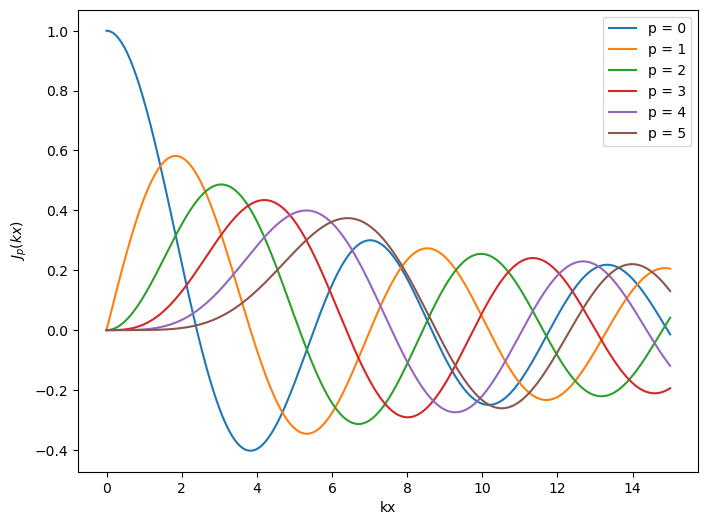

In [16]:
import numpy as np 
import matplotlib.pyplot as plt 
import scipy as sp 

# Constants
orders = [0, 1, 2, 3, 4, 5]
k = 1.0

x = np.linspace(0, 15, num = 1000)

fig, axes = plt.subplots(1, 1, figsize=(8,6))
for p in orders:
    axes.plot(x, sp.special.jn(p, x), label=f"p = {p}")
axes.legend(loc="upper right")
axes.set_ylabel(r"$J_p(kx)$")
axes.set_xlabel("kx")

plt.show()


## Bessel functions of the second kind

Properties of Bessel functions of the second kind:
- For all values of $p$, $\lim_{x\rightarrow 0+} Y_p(x)= -\infty$.
- All $Y_p(kx)$ functions have an infinite number of zeros.

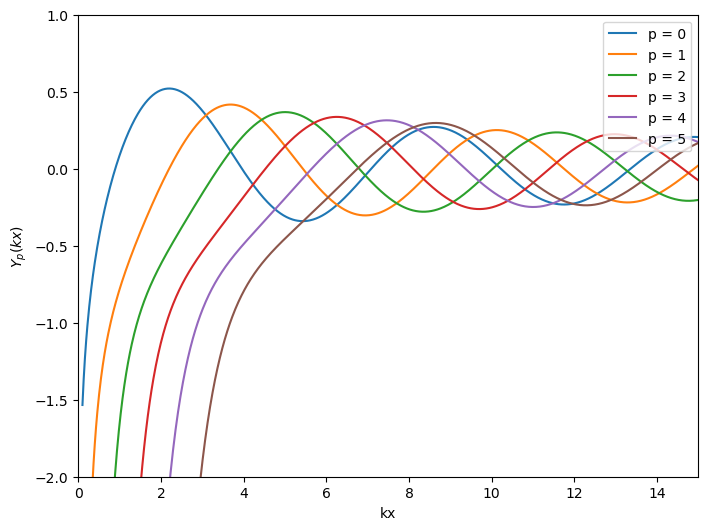

In [33]:
x = np.linspace(0.1, 15, num = 1000)

fig, axes = plt.subplots(1, 1, figsize=(8,6))
for p in orders:
    axes.plot(x, sp.special.yn(p, x), label=f"p = {p}")
axes.legend(loc="upper right")
axes.set_ylabel(r"$Y_p(kx)$")
axes.set_xlabel("kx")
axes.set_xlim(0, 15)
axes.set_ylim(-2, 1)

plt.show()

## Zeros of Bessel functions

The zeros for Bessel functions are not easily calculated and must be determined numerically.

### First kind

The first 5 zeros for J_p(kx) are [ 2.40482556  5.52007811  8.65372791 11.79153444 14.93091771].


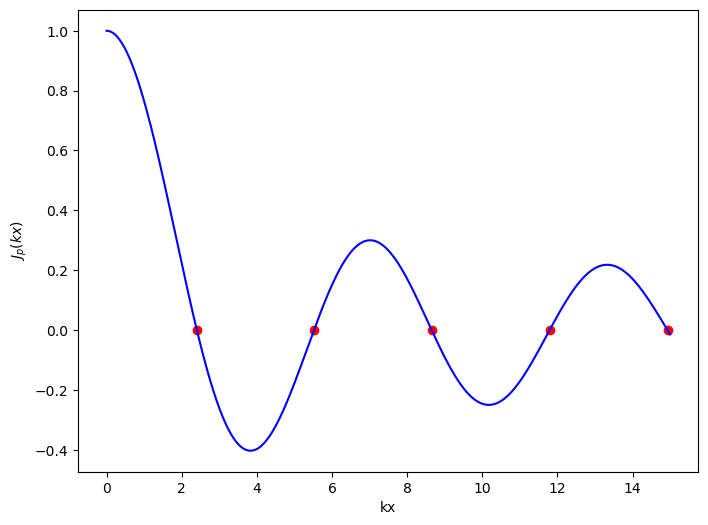

In [54]:
j0z = sp.special.jn_zeros(0,5)

print(fr"The first 5 zeros for J_p(kx) are {j0z}.")

x = np.linspace(0, 15, num = 1000)

fig, axes = plt.subplots(1, 1, figsize=(8,6))
axes.plot(x, sp.special.jn(0, x), 'b')
axes.scatter(j0z, np.zeros(j0z.size), color='r')
axes.set_ylabel(r"$J_p(kx)$")
axes.set_xlabel("kx")

plt.show()

Others can also be calculated without patterns:

In [57]:
j0z = sp.special.jn_zeros(0,5)
print(fr"The first 5 zeros for J_0(kx) are {j0z}.")
j1z = sp.special.jn_zeros(1,5)
print(fr"The first 5 zeros for J_1(kx) are {j1z}.")
j2z = sp.special.jn_zeros(2,5)
print(fr"The first 5 zeros for J_2(kx) are {j2z}.")


The first 5 zeros for J_0(kx) are [ 2.40482556  5.52007811  8.65372791 11.79153444 14.93091771].
The first 5 zeros for J_1(kx) are [ 3.83170597  7.01558667 10.17346814 13.32369194 16.47063005].
The first 5 zeros for J_2(kx) are [ 5.1356223   8.41724414 11.61984117 14.79595178 17.95981949].


### Second kind

The first 5 zeros for Y_p(kx) are [ 0.89357697  3.95767842  7.08605106 10.22234504 13.36109747].


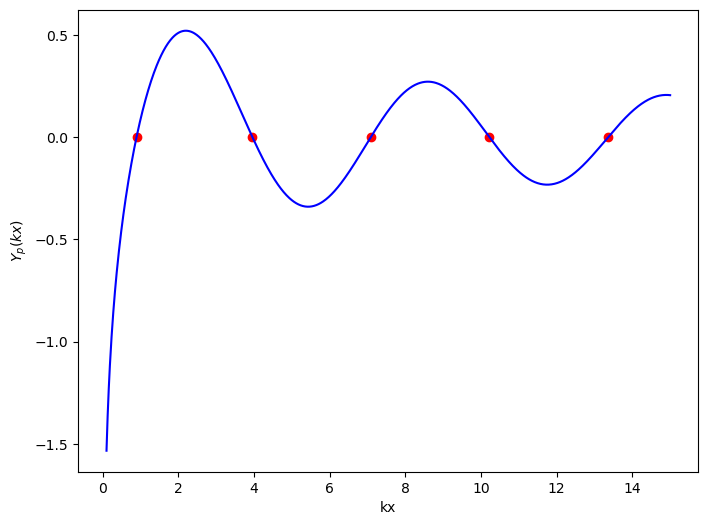

In [60]:
y0z = sp.special.yn_zeros(0,5)

print(fr"The first 5 zeros for Y_p(kx) are {y0z}.")

x = np.linspace(0.1, 15, num = 1000)

fig, axes = plt.subplots(1, 1, figsize=(8,6))
axes.plot(x, sp.special.yn(0, x), 'b')
axes.scatter(y0z, np.zeros(y0z.size), color='r')
axes.set_ylabel(r"$Y_p(kx)$")
axes.set_xlabel("kx")

plt.show()


## Bessel expansion

Consider the simple function:

$$
y(x) = x
$$

It is defined for $0 < x < a$. We want to express it as a Bessel expansion:

$$
y(x) = \sum_{n = 0}^{\infty} A_n J_p\left(\frac{\alpha_{p,n}}{a}x\right)
$$

For any value of $p$, the Bessel function form a complete basis. So we have to find to the coefficients $A_n$ that correspond to $y(x)$ using:

$$
A_n = \frac{2}{a^2 J_{p+1}^2(\alpha_{p,n})}\int_0^a x J_p\left(\frac{\alpha_{p,n}}{a}x\right) dx
$$

In this example, we will use $a = 3$ and $p = 1$. We will consider the first 30 values of $n$ instead of letting the sum go to infinity.

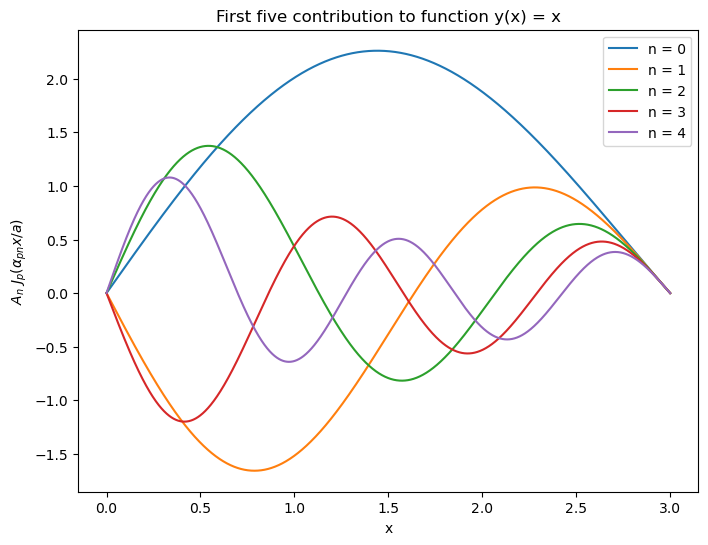

In [108]:
import numpy as np 
import matplotlib.pyplot as plt 
import scipy as sp 

# Constants
p = 1
a = 3
Nzeros = 30     # Number of zeros to include
Nint = 2000     # Number of point in integral

# Calculate the zeros
alpha_pn = sp.special.jn_zeros(p, Nzeros)

# Define function to integrate. Here, y(x) = x
def fct(x, a, p, alpha):
    return x**2 * sp.special.jn(p, alpha*x/a)

# Define the rectangular integral method
def integrate_rect(f, a, p, alpha, N):
    h = a/N
    integral = 0.0
    x = np.array([], dtype='float')
    for k in range(1,N+1):
        xk = (2*k-1)*h/2
        x = np.append(x, xk)
        integral = integral + h*f(xk, a, p, alpha)
    return [integral, x, h]

# Calculate the coefficient 
def calc_coef(f, a, p, alpha_pn):
    An = np.zeros(alpha_pn.size)
    
    for i in range(alpha_pn.size):
        pre = 2/a**2/sp.special.jn(p+1, alpha_pn[i])**2

        integral, _, _ = integrate_rect(f, a, p, alpha_pn[i], Nint)

        An[i] = pre*integral

    return An 

An = calc_coef(fct, a, p, alpha_pn)

# Calculate contributions
x = np.linspace(0, a, num=Nint)

# Each column corresponds to the contribution from a different n. Last column is total.
def calc_contribs(An, a, p, x, alpha_pn):
    contrib = np.zeros((Nint, Nzeros+1))

    for i in range(Nzeros):
        contrib[:,i] = An[i]*sp.special.jn(p,alpha_pn[i]*x/a)
        contrib[:,-1] += An[i]*sp.special.jn(p,alpha_pn[i]*x/a)

    return contrib

contrib = calc_contribs(An, a, p, x, alpha_pn)

# Plot First 5 contributions
fig1, axes1 = plt.subplots(1, 1, figsize=(8,6))
axes1.plot(x, contrib[:,0], label="n = 0")
axes1.plot(x, contrib[:,1], label="n = 1")
axes1.plot(x, contrib[:,2], label="n = 2")
axes1.plot(x, contrib[:,3], label="n = 3")
axes1.plot(x, contrib[:,4], label="n = 4")
axes1.legend(loc='upper right')
axes1.set_xlabel("x")
axes1.set_ylabel(r"$A_n$ $J_p(\alpha_{pn}x/a)$")
axes1.set_title("First five contribution to function y(x) = x")

plt.show()


We can track how the approximation evolves as we add more terms.

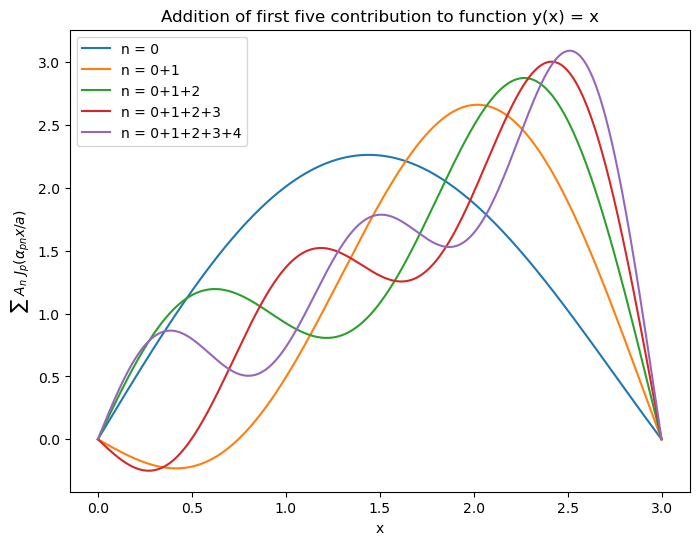

In [109]:
# Plot evolving expansion
fig2, axes2 = plt.subplots(1, 1, figsize=(8,6))
y_approx = contrib[:,0]
axes2.plot(x, y_approx, label="n = 0")
y_approx += contrib[:,1]
axes2.plot(x, y_approx, label="n = 0+1")
y_approx += contrib[:,2]
axes2.plot(x, y_approx, label="n = 0+1+2")
y_approx += contrib[:,3]
axes2.plot(x, y_approx, label="n = 0+1+2+3")
y_approx += contrib[:,4]
axes2.plot(x, y_approx, label="n = 0+1+2+3+4")
axes2.legend(loc='upper left')
axes2.set_xlabel("x")
axes2.set_ylabel(r"$\sum$ $A_n$ $J_p(\alpha_{pn}x/a)$")
axes2.set_title("Addition of first five contribution to function y(x) = x")



plt.show()


The total approximation is

Text(0.5, 1.0, 'Approximation of y(x) = x with 30 terms.')

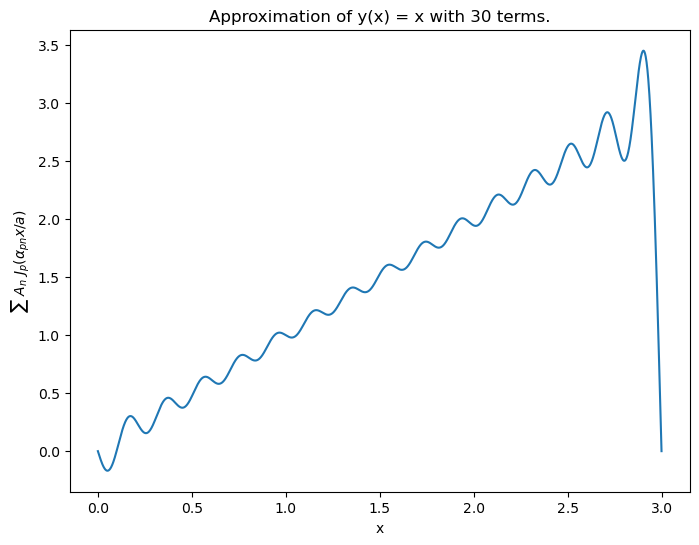

In [110]:
fig3, axes3 = plt.subplots(1, 1, figsize=(8,6))
axes3.plot(x, contrib[:,-1])
axes3.set_xlabel("x")
axes3.set_ylabel(r"$\sum$ $A_n$ $J_p(\alpha_{pn}x/a)$")
axes3.set_title(f"Approximation of y(x) = x with {Nzeros} terms.")
